In [1]:
%reset
import numpy as np
#import MDAnalysis
#from MDAnalysis.analysis import helix_analysis as hel
import matplotlib.pyplot as plt
import dnaMD
import fileinput as fi
from pylab import *
%matplotlib inline

def rm_neun(vari):
    indizes = np.array([])
    for x in range(len(vari)):
        nmmr = np.where(vari[x] == 99.99)
        indizes = np.append(indizes,nmmr)

    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for d in range(len(vari)):
        for y in range(len(indexes)):
            #print(indexes[y])
            vari[d] = np.delete(vari[d],indexes[y])
            
    return vari

def rm_neun_axis(vari):
    indizes = np.array([])
    #for x in range(len(vari["bps"]["1"]["helical x-axis"])):
    for x in range(1,19):
        nmmr = np.where(vari["bps"][str(x)]["helical x-axis"] == 99.99)
        indizes = np.append(indizes,nmmr)

    #indizes = np.append(indizes,2001)
    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for d in range(1,19):
        for y in range(len(indexes)):
            #print(indexes[y])
            vari["bps"][str(d)]["helical x-axis"] = np.delete(vari["bps"][str(d)]["helical x-axis"],indexes[y])
            vari["bps"][str(d)]["helical x-axis"] = np.delete(vari["bps"][str(d)]["helical y-axis"],indexes[y])
            vari["bps"][str(d)]["helical x-axis"] = np.delete(vari["bps"][str(d)]["helical z-axis"],indexes[y])
            
            
            
    return vari

def rm_neun_axis_new(risevari,bendvari):
    indizes = np.array([])
    for x in range(len(risevari)):
        nmmr = np.where(risevari[x] == 99.99)
        indizes = np.append(indizes,nmmr)

    indexes = np.sort(indizes)
    indexes = np.flip(indexes)
    indexes = indexes.astype(int)
    indexes = list(dict.fromkeys(indexes))
       
    for y in range(len(indexes)):
        bendvari = np.delete(bendvari,indexes[y])
        #print(indexes[y])
            
    return bendvari

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y


In [14]:
#np.where(avg.data['bps']['1']['helical x-axis']==99.99)


(array([  31,   91,  241,  462,  884,  918,  967, 1003, 1035, 1225, 1491,
        1620, 1649, 1700, 1701, 1702, 1703, 1773, 1804, 1805, 1806, 1822,
        1827, 1833, 1906, 1907, 1908, 1909, 2027, 2045, 2226, 2555, 2592,
        2872, 3059, 3060, 3061, 3062, 3063, 3064, 3065, 3066, 3067, 3068,
        3069, 3070, 3071, 3122, 3433, 3453, 3587, 3606, 3607, 3696, 3699,
        3700, 3922, 4062, 4260, 4266, 4267, 4268, 4269, 4270, 4272, 4278,
        4466, 4540, 4947, 5024, 5066, 5344, 5351, 5352, 5401, 5593, 5602,
        5704, 5824, 5905, 5992, 6150, 6151, 6170, 6362, 6363, 6434, 6438,
        6492, 6667, 6668, 6868, 6869, 6870, 7365, 7366, 7367, 7411, 7440,
        7449, 7595, 7596, 7598, 7713, 7725, 7801, 7802, 8074, 8085, 8124,
        8263, 8444, 8698, 8925, 8935, 8936, 8974, 9691, 9774, 9775, 9776,
        9780, 9903]),)

In [7]:
avg = dnaMD.DNA(20) 
avg.set_helical_axis('../OL3_even_MHrun/HelAxis_evenMH.dat')
#avg.set_helical_axis('../OL3_even_MHrun/HelAxis_evnavg.dat')

avg.generate_smooth_axis(smooth=500, spline=3, fill_point=6, cut_off_angle=180);
#avg.write_haxis_pdb(filename='x3dna_helax.pdb',step_range=True,step = [1,19], write_smooth_axis=True)

#avg.calculate_curvature_tangent(store_tangent=True)


Reading file : ../OL3_even_MHrun/HelAxis_evenMH.dat
Reading frame 9000
Finished reading.... Total number of frame read =  10000
Fitting spline curve on helical axis of frame 900 out of 10000 frames

ValueError: Invalid inputs.

In [4]:
rangen = [1,19]
#rangen = [2,18]
#rangen = [3,17]
#rangen = [4,16]
#rangen = [5,15]
#avgangle = avg.calculate_angle_bw_tangents([3,17])
avgangle = avg.calculate_angle_bw_tangents(rangen)


avgangle = np.degrees(avgangle)

print(avgangle)

[5.75621279]


In [17]:
Desodd = dnaMD.DNA(20) 
Desodd.set_helical_axis('../DESRESodd/HelAxis_tst.dat')
bscdna = dnaMD.DNA(20) 
#bscdna.set_helical_axis('ol3-odd-v2/HelAxis_avg.dat')
bscdna.set_helical_axis('../PCA/DNA/HelAxis_dna_w.dat')

Desodd.generate_smooth_axis(smooth=500, spline=3, fill_point=6, cut_off_angle=180);
#Desodd.generate_smooth_axis(smooth=500, spline=3, fill_point=6);
bscdna.generate_smooth_axis(smooth=500, spline=3, fill_point=6, cut_off_angle=180);

#Desodd.write_haxis_pdb(filename='desresodd/axisDeodd.pdb',step_range=True,step = [3,17], write_smooth_axis=True)


Reading file : ../DESRESodd/HelAxis_tst.dat
Reading frame 1000
Finished reading.... Total number of frame read =  1909

Reading file : ../PCA/DNA/HelAxis_dna_w.dat
Reading frame 1000
Finished reading.... Total number of frame read =  1986
Fitting spline curve on helical axis of frame 1000 out of 1909 frames
Finished spline curve fitting...
Fitting spline curve on helical axis of frame 1000 out of 1986 frames
Finished spline curve fitting...



Reading file : ../DESRESodd/L-BPH_tst.dat
Reading frame 2000
Finished reading.... Total number of frame read =  2001
DNA: 19.0 ± 10.0
RNA: 22.0 ± 13.0


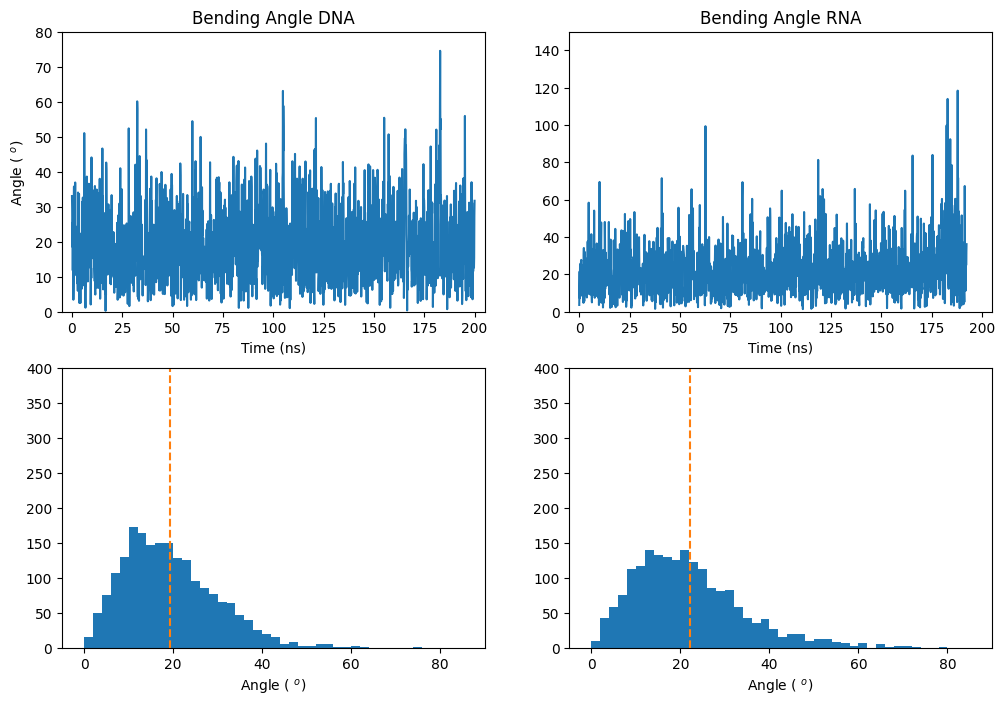

In [20]:
Deodd=dnaMD.DNA(20)
Deodd.set_base_step_parameters('../DESRESodd/L-BPH_tst.dat',parameters='all',bp_step=[1, 19],step_range=True,helical=True) 
rangen = [6,15]
Deoddrise, bp_idx = Deodd.get_parameters('h-rise',rangen,bp_range=True)


Desodd.calculate_curvature_tangent(store_tangent=True)
bscdna.calculate_curvature_tangent(store_tangent=True)

Deoddangle = Desodd.calculate_angle_bw_tangents([3,17])
#Deoddangle = Desodd.calculate_angle_bw_tangents([10,11])
Deoddangle = np.degrees(Deoddangle)

bscdnaangle = bscdna.calculate_angle_bw_tangents([3,17])
#bscdnaangle = bscdna.calculate_angle_bw_tangents([10,11])
bscdnaangle = np.degrees(bscdnaangle)

Deoddangle = rm_neun_axis_new(Deoddrise,Deoddangle)

#bns = np.linspace(0,80,33)
bns = np.linspace(0,80,41)

relevantD = np.where(np.logical_not(np.isnan(bscdnaangle)) == True)[0]
print('DNA: ' + str(round(np.mean(bscdnaangle[relevantD]),0)) + u" \u00B1 " + str(round(np.std(bscdnaangle[relevantD]),0)))

relevantA = np.where(np.logical_not(np.isnan(Deoddangle)) == True)[0]
print('RNA: ' + str(round(np.mean(Deoddangle[relevantA]),0)) + u" \u00B1 " + str(round(np.std(Deoddangle[relevantA]),0)))


plt.figure(figsize=(12,8))
subplot(2,2,1)
plt.title('Bending Angle DNA')
plt.plot(bscdna.time/1000, bscdnaangle)
plt.xlabel('Time (ns)');plt.ylabel('Angle ( $^o$)')
plt.axis([-5, 205,0,80])

subplot(2,2,3)
plt.hist(bscdnaangle,bins=bns)
plt.xlabel('Angle ( $^o$)')
plt.axis([-5,90,0,400])
plt.plot([np.mean(bscdnaangle[relevantD]), np.mean(bscdnaangle[relevantD])], [0,440], "--");

subplot(2,2,2)
plt.title('Bending Angle RNA')
plt.plot(Desodd.time[0:len(Deoddangle)]/1000, Deoddangle)
plt.xlabel('Time (ns)')
plt.axis([-5, 205,0,150])

subplot(2,2,4)
c,ed,h=plt.hist(Deoddangle,bins=bns)
plt.xlabel('Angle ( $^o$)')
plt.axis([-5,90,0,400])
plt.plot([np.mean(Deoddangle[relevantA]), np.mean(Deoddangle[relevantA])], [0,440], "--");

#plt.savefig('bending_DNA_RNA.png',dpi=1200)
#plt.savefig('bending_cutoff.png',dpi=1200)

In [27]:
np.size(Desodd.time)

1909

In [18]:
# Careful! only use once to add a line of 99.99 to timesteps where
# a basepair is missing
#fff

#dateenamee = "desreseven/HelixRad_g.dat"  
#dateenamee = "desresodd/HelAxis_tst.dat" 
#dateenamee = "PCA/DNA/HelAxis_dna.dat"
dateenamee = "../OL3_even_MHrun/HelAxis_evenMH.dat"
numb = "# Time ="#'99.99'
liste = np.array([])

with open(dateenamee) as myFile:
    for num, line in enumerate(myFile, 1):
        if numb in line:
            liste = np.append(liste,num)

diffe = np.diff(liste)
result = np.where(diffe == 20)
result = result[0]

for x in result:
    if x==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>0 and x<10:
        srch = '# Time =       '+str(x)+'00.00000'
        rplc = '# Time =       '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>9 and x<100:
        srch = '# Time =      '+str(x)+'00.00000'
        rplc = '# Time =      '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>99 and x<1000:
        srch = '# Time =     '+str(x)+'00.00000'
        rplc = '# Time =     '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif x>999 and x<10000:
        srch = '# Time =    '+str(x)+'00.00000'
        rplc = '# Time =    '+str(x)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')
            
result19 = np.where(diffe == 19)
result19 = result19[0]

for y in result19:
    if y==0:
        srch = '# Time =         0.00000'
        rplc = '# Time =         0.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>0 and y<10:
        srch = '# Time =       '+str(y)+'00.00000'
        rplc = '# Time =       '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>9 and y<100:
        srch = '# Time =      '+str(y)+'00.00000'
        rplc = '# Time =      '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>99 and y<1000:
        srch = '# Time =     '+str(y)+'00.00000'
        rplc = '# Time =     '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
    elif y>999 and y<10000:
        srch = '# Time =    '+str(y)+'00.00000'
        rplc = '# Time =    '+str(y)+'00.00000\n99.99   99.99   99.99   99.99   99.99   99.99\n99.99   99.99   99.99   99.99   99.99   99.99'
        
    with fi.FileInput(dateenamee, inplace=True) as File:
        for line in File:
            print(line.replace(srch, rplc),end='')

In [17]:
## DNA File Zeiten umschreiben
dateenamee = "../OL3_even_MHrun/HelAxis_evenMH.dat"

with open(dateenamee, 'r') as file:
    data = file.readlines()

liste = liste.astype(int)
for x in liste:
    d = int(np.where(liste == x)[0])
    if d==0:
        data[x-1] = '# Time =         0.00000\n'
    elif d>0 and d<10:
        data[x-1] = '# Time =       '+str(d)+'00.00000\n'
        
    elif d>9 and d<100:
        data[x-1] = '# Time =      '+str(d)+'00.00000\n'
        
    elif d>99 and d<1000:
        data[x-1] = '# Time =     '+str(d)+'00.00000\n'
        
    elif d>999 and d<10000:
        data[x-1] = '# Time =    '+str(d)+'00.00000\n'
        
with open(dateenamee, 'w') as file:
    file.writelines( data )

/var/folders/j2/qm5b0qr10c94x4pnd9hdjcmh0000gn/T/ipykernel_83595/2209887261.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  d = int(np.where(liste == x)[0])
